# 09 — Inferencia Bayesiana

**Objetivos de aprendizagem:** atualizar distribuições a priori em posteriores e produzir probabilidades de decisões

**Pré-requisitos:** Notebooks 05–07

**Origem:** Aprofundamento novo, fora do escopo principal dos slides; pressupõe Bayes do Notebook 05. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/09_inferencia_bayesiana.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_inferencia_bayesiana.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Modelo e atualização

Posterior ∝ verossimilhança × prior. Em inferência bayesiana, a incerteza sobre parâmetros é representada por uma distribuição; uma prior não precisa ser subjetiva, mas deve ser declarada e justificada.

In [2]:
from scipy import stats
# Exemplo sintético: 18 sucessos em 30 tentativas, modelo Binomial
n=30;y=18;a0,b0=2,2
a1=a0+y;b1=b0+n-y
print('prior Beta',a0,b0,'posterior Beta',a1,b1)
print('média posterior',a1/(a1+b1))

prior Beta 2 2 posterior Beta 20 14
média posterior 0.5882352941176471


## 2. Beta–Binomial e intervalo de credibilidade

Com probabilidade θ de sucesso e prior Beta(a,b), observar y sucessos em n tentativas dá posterior Beta(a+y,b+n−y). Um intervalo de credibilidade de 95% contém 95% de massa posterior *condicional ao modelo e à prior*.

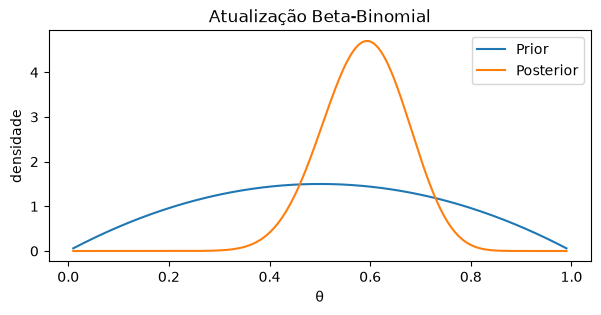

Credibilidade 95%: [0.42139372 0.74523818]


In [3]:
eixo=np.linspace(.01,.99,400)
fig,ax=plt.subplots(figsize=(7,3));ax.plot(eixo,stats.beta.pdf(eixo,a0,b0),label='Prior');ax.plot(eixo,stats.beta.pdf(eixo,a1,b1),label='Posterior');ax.legend();ax.set(xlabel='θ',ylabel='densidade',title='Atualização Beta-Binomial');fig.savefig(OUTPUTS / '09_prior_posterior_beta.png', dpi=160, bbox_inches='tight');plt.show()
print('Credibilidade 95%:',stats.beta.ppf([.025,.975],a1,b1))

## 3. Sensibilidade à prior

Para dados escassos, a escolha da prior pode alterar substancialmente as conclusões. Comparar priors plausíveis é parte da análise, não um inconveniente a esconder.

In [4]:
priors=[(1,1),(2,2),(10,10)]
for a,beta in priors:
 print((a,beta),'média posterior',round((a+y)/(a+beta+n),3))

(1, 1) média posterior 0.594
(2, 2) média posterior 0.588
(10, 10) média posterior 0.56


In [5]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame([{'prior_a':a,'prior_b':beta,'posterior_a':a+y,'posterior_b':beta+n-y,'media_posterior':(a+y)/(a+beta+n)} for a,beta in priors]).to_csv(OUTPUTS / '09_sensibilidade_prior.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 4. Probabilidade posterior de uma hipótese

Podemos perguntar P(θ>0,5 | dados), mas o resultado depende das hipóteses probabilísticas e dos dados observados. Isso difere diretamente de p-valor frequentista.

In [6]:
prob=stats.beta.sf(.5,a1,b1)
print('P(θ > 0,5 | dados, modelo e prior)=',prob)

P(θ > 0,5 | dados, modelo e prior)= 0.8518968157004565


## 5. Comparação de taxas — simulação posterior

Simulações de duas posteriores permitem estimar a probabilidade de uma taxa superar a outra. O exemplo é sintético e assume independência condicional e modelos Beta–Binomial apropriados.

In [7]:
pA=RNG.beta(21,21,50000);pB=RNG.beta(26,16,50000)
print('P(taxa B > taxa A | modelos e dados)=',np.mean(pB>pA))
print('diferença posterior média',np.mean(pB-pA))

P(taxa B > taxa A | modelos e dados)= 0.86638
diferença posterior média 0.11875554830104386


In [8]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'quantidade':['media_posterior_A','media_posterior_B','probabilidade_B_maior_A','diferenca_media_B_menos_A'], 'valor':[pA.mean(),pB.mean(),np.mean(pB>pA),np.mean(pB-pA)]}).to_csv(OUTPUTS / '09_comparacao_posterior.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Posterior sob prior uniforme

**Solução comentada:**

In [9]:
a,beta=1,1;sucessos,tentativas=7,10
post=(a+sucessos,beta+tentativas-sucessos)
assert post==(8,4)
print('Posterior:',post,'esperança:',post[0]/sum(post))

Posterior: (8, 4) esperança: 0.6666666666666666


**Interpretação:** Uma prior uniforme Beta(1,1) seguida de sete sucessos em dez tentativas dá Beta(8,4).

## Erros comuns e limites

Não apresente resultados posteriores sem explicitar priors, verossimilhança e hipóteses. Técnicas computacionais gerais (MCMC) exigem verificação de convergência e ficam como trilha futura.

## Consulta Rápida

`stats.beta.pdf(theta,a,b)` · `stats.beta.ppf([.025,.975],a,b)` · `stats.beta.sf(limite,a,b)` · posterior Beta(a+y,b+n−y).

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Sensibilidade da posterior à prior

A interpretação bayesiana é condicional ao modelo, à prior e aos dados. Para a conjugação Beta–Binomial, `prior=Beta(a,b)` e `y` sucessos em `n` tentativas resultam em `posterior=Beta(a+y, b+n-y)`. Em amostras pequenas, diferentes priors podem produzir conclusões relevantes distintas.

In [10]:
from scipy import stats
sucessos_novos=3;n_novo=5
priors_novos={'uniforme':(1,1),'centrada_05':(10,10),'otimista':(8,2)}
linhas=[]
for nome,(a,beta) in priors_novos.items():
    ap=a+sucessos_novos;bp=beta+n_novo-sucessos_novos
    linhas.append({'prior':nome,'media_posterior':ap/(ap+bp),
                   'p_theta_maior_05':stats.beta.sf(.5,ap,bp)})
quadro_priors=pd.DataFrame(linhas)
display(quadro_priors.round(3))
assert quadro_priors['media_posterior'].between(0,1).all()

,prior,media_posterior,p_theta_maior_05
0,uniforme,0.571,0.656
1,centrada_05,0.520,0.581
2,otimista,0.733,0.971


### Exercício resolvido

**Pergunta:** por que testar mais de uma prior quando há apenas cinco observações?

**Solução:** porque pouca informação nos dados pode deixar a posterior sensível às crenças anteriores. A análise de sensibilidade torna explícito quanto as conclusões dependem dessas escolhas.